# Notebook 5 — SHAP Explainability and Model Comparison

This notebook explains the tuned document ranker with SHAP and compares its development retrieval performance with the lexical and dense baselines. SHAP attributes each ranking score to explicit features; it does not explain the internal token-by-token behavior of Qwen.

In [1]:
from pathlib import Path
import json, sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
(ROOT / 'results' / 'figures').mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Frozen test split accessed:', False)

Project root: <PROJECT_ROOT>
Frozen test split accessed: False


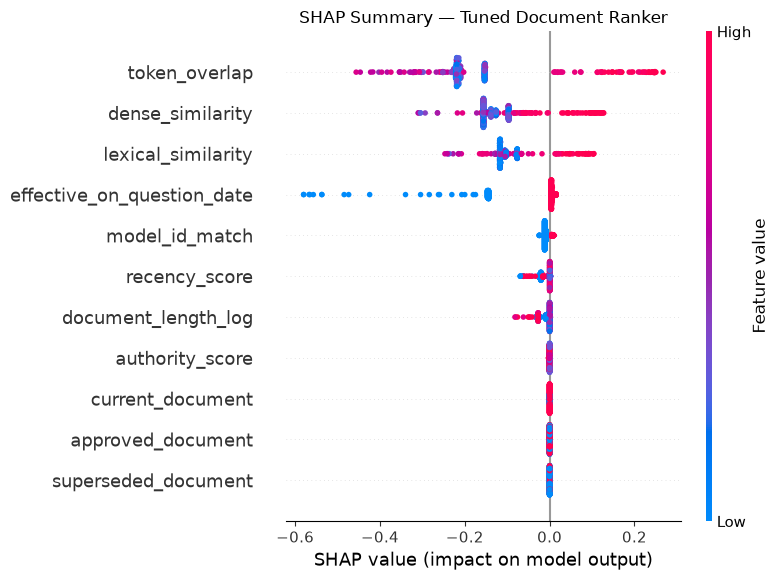

In [2]:
import json, joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from src.local_pipeline import FEATURE_NAMES

features = pd.read_csv(ROOT / 'results' / 'pair_features_train_development.csv')
development = features[features['split'] == 'development'].copy()
model = joblib.load(ROOT / 'results' / 'optuna_ranker.joblib')
sample = development.sample(n=min(500, len(development)), random_state=699)
explainer = shap.TreeExplainer(model)
explanation = explainer(sample[FEATURE_NAMES])
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]
shap.plots.beeswarm(explanation, max_display=len(FEATURE_NAMES), show=False)
plt.title('SHAP Summary — Tuned Document Ranker')
plt.tight_layout()
plt.savefig(ROOT / 'results' / 'figures' / 'shap_summary.png', dpi=180, bbox_inches='tight')
plt.show()

In [3]:
importance = pd.DataFrame({
    'feature': FEATURE_NAMES,
    'mean_absolute_shap': np.abs(explanation.values).mean(axis=0),
}).sort_values('mean_absolute_shap', ascending=False)
importance.to_csv(ROOT / 'results' / 'shap_feature_importance.csv', index=False)
importance

,feature,mean_absolute_shap
2,token_overlap,0.206957
0,dense_similarity,0.130161
1,lexical_similarity,0.104012
4,effective_on_question_date,0.047465
3,model_id_match,0.010393
9,recency_score,0.008438
10,document_length_log,0.008386
8,authority_score,0.000232
5,current_document,0.000049
6,superseded_document,0.000000


,TF-IDF,Nomic dense,Optuna ranker
hit_rate_at_5,1.000000,1.0000,1.000000
recall_at_5,0.958333,1.0000,0.979167
precision_at_5,0.283333,0.3000,0.291667
mean_reciprocal_rank,0.617361,0.8125,0.958333


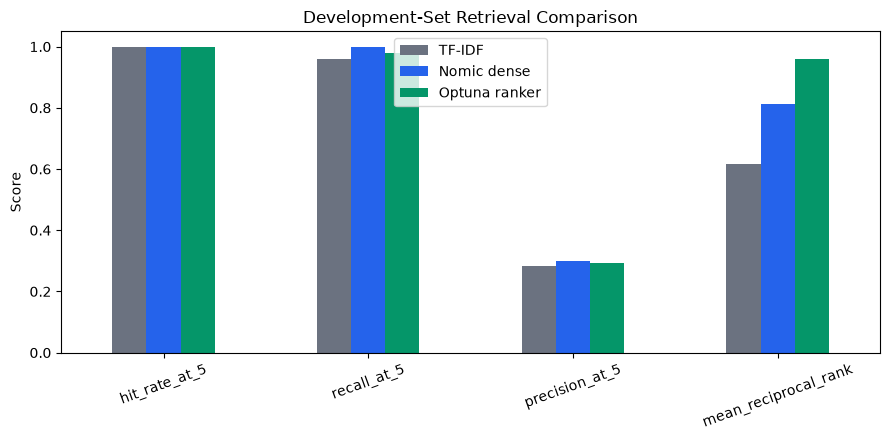

In [4]:
tfidf = json.loads((ROOT / 'results' / 'tfidf_development_k5_summary.json').read_text())['metrics']
dense = json.loads((ROOT / 'results' / 'ollama_dense_development_k5_summary.json').read_text())['metrics']
tuned = json.loads((ROOT / 'results' / 'optuna_development_metrics.json').read_text())
keys = ['hit_rate_at_5', 'recall_at_5', 'precision_at_5', 'mean_reciprocal_rank']
comparison = pd.DataFrame({
    'TF-IDF': [tfidf[k] for k in keys],
    'Nomic dense': [dense[k] for k in keys],
    'Optuna ranker': [tuned[k] for k in keys],
}, index=keys)
display(comparison)
ax = comparison.plot.bar(figsize=(9, 4.5), color=['#6B7280','#2563EB','#059669'])
ax.set_ylim(0, 1.05); ax.set_ylabel('Score'); ax.set_title('Development-Set Retrieval Comparison')
ax.tick_params(axis='x', rotation=20); ax.figure.tight_layout()
ax.figure.savefig(ROOT / 'results' / 'figures' / 'all_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

In [5]:
top_features = importance.head(5).to_dict(orient='records')
summary = {
    'explanation_method': 'SHAP TreeExplainer',
    'explained_component': 'feature-based document ranker',
    'sample_rows': len(sample),
    'top_features': top_features,
    'test_set_accessed': False,
}
(ROOT / 'results' / 'shap_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
summary

{'explanation_method': 'SHAP TreeExplainer',
 'explained_component': 'feature-based document ranker',
 'sample_rows': 500,
 'top_features': [{'feature': 'token_overlap',
   'mean_absolute_shap': 0.2069573406656741},
  {'feature': 'dense_similarity', 'mean_absolute_shap': 0.1301612318321191},
  {'feature': 'lexical_similarity', 'mean_absolute_shap': 0.10401163895760392},
  {'feature': 'effective_on_question_date',
   'mean_absolute_shap': 0.04746515888301918},
  {'feature': 'model_id_match', 'mean_absolute_shap': 0.010392550557148647}],
 'test_set_accessed': False}

## Interpretation and limits

Positive or negative SHAP values indicate how a feature moved a document's relevance score relative to the model's baseline. Global importance does not prove causation, fairness, or correctness. Reviewers should inspect individual explanations, retrieval evidence, and temporal/status controls before relying on an answer.